In [5]:
import os
import torch
import torch.nn.functional as F
import numpy as np
import evaluate
from datasets import load_dataset
from PIL import Image
from transformers import (
    AutoImageProcessor,
    AutoModelForImageClassification,
    TrainingArguments,
    Trainer,
    DefaultDataCollator,
    pipeline, 
    AutoModelForCausalLM, 
    AutoTokenizer
)
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# Environment Setup & Hardware Accelerator Detection
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Active Accelerator Device: {device}")

C:\Users\jayog\Documents\INFO4000\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Active Accelerator Device: cpu


In [2]:
# Load Dataset from 'Objects' folder
dataset_dir = "Objects"

# Load image dataset using Hugging Face's imagefolder builder
raw_dataset = load_dataset("imagefolder", data_dir=dataset_dir)
print(f"Dataset structure:\n{raw_dataset}")

# Extract class label mappings
labels = raw_dataset["train"].features["label"].names
num_labels = len(labels)
label2id = {label: i for i, label in enumerate(labels)}
id2label = {i: label for i, label in enumerate(labels)}

print(f"\nDiscovered {num_labels} object classes: {labels}")

# Preprocessing Transforms via AutoImageProcessor
model_checkpoint = "google/vit-base-patch16-224"
image_processor = AutoImageProcessor.from_pretrained(model_checkpoint)

Dataset structure:
DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 14034
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 3000
    })
})

Discovered 6 object classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [3]:
def transform_batch(example_batch):
    images = [img.convert("RGB") for img in example_batch["image"]] # Ensure images are in RGB mode
    inputs = image_processor(images, return_tensors="pt") # Applies image resizing, normalization, and tensor conversion
    inputs["label"] = example_batch["label"] # matching the original ViT pretraining pipeline.
    return inputs

In [4]:
# Apply transformations dynamically on the fly
transformed_dataset = raw_dataset.with_transform(transform_batch)

# Model Instantiation &amp; Evaluation Metric Definition
model = AutoModelForImageClassification.from_pretrained(
    model_checkpoint,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True # Re-initializes classification head for custom classes
)

accuracy_metric = evaluate.load("accuracy")

[transformers] You passed `num_labels=6` which is incompatible to the `id2label` map of length `1000`.
Loading weights: 100%|██████████| 200/200 [00:00<00:00, 1455.76it/s]
[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                          
------------------+----------+------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([6])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([6, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


In [5]:
def compute_metrics(eval_pred):
    logits, labels_gt = eval_pred
    predictions = np.argmax(logits, axis=-1) # Converts raw unnormalized logits to discrete class predictions via argmax.
    return accuracy_metric.compute(predictions=predictions, references=labels_gt) # Computes top-1 accuracy on evaluation predictions.

In [6]:
# Training Arguments & Trainer Orchestration
for param in model.vit.parameters(): 
    param.requires_grad = False

training_args = TrainingArguments(
    output_dir="./vit-objects-finetuned",
    per_device_train_batch_size=32,  # Increased batch size for faster CPU throughput
    per_device_eval_batch_size=32,
    num_train_epochs=1,              # 1 epoch = ~438 steps, plenty for 14,000 images
    learning_rate=1e-3,              # Higher learning rate for classifier head
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_steps=50,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    greater_is_better=True,
    remove_unused_columns=False,
    fp16=False,
    use_cpu=True,
    dataloader_pin_memory=False      # Suppresses the pin_memory UserWarning
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=transformed_dataset["train"],
    eval_dataset=transformed_dataset["test"],
    processing_class=image_processor,
    data_collator=DefaultDataCollator(),
    compute_metrics=compute_metrics
)
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy
1,0.156312,0.172536,0.942000


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  6.37it/s]
[transformers] There were missing keys in the checkpoint model loaded: ['vit.layers.0.attention.q_proj.weight', 'vit.layers.0.attention.q_proj.bias', 'vit.layers.0.attention.k_proj.weight', 'vit.layers.0.attention.k_proj.bias', 'vit.layers.0.attention.v_proj.weight', 'vit.layers.0.attention.v_proj.bias', 'vit.layers.0.attention.o_proj.weight', 'vit.layers.0.attention.o_proj.bias', 'vit.layers.0.layernorm_before.weight', 'vit.layers.0.layernorm_before.bias', 'vit.layers.0.layernorm_after.weight', 'vit.layers.0.layernorm_after.bias', 'vit.layers.0.mlp.fc1.weight', 'vit.layers.0.mlp.fc1.bias', 'vit.layers.0.mlp.fc2.weight', 'vit.layers.0.mlp.fc2.bias', 'vit.layers.1.attention.q_proj.weight', 'vit.layers.1.attention.q_proj.bias', 'vit.layers.1.attention.k_proj.weight', 'vit.layers.1.attention.k_proj.bias', 'vit.layers.1.attention.v_proj.weight', 'vit.layers.1.attention.v_proj.bias', 'vit.layers.1.attention.o_proj.weight', 

TrainOutput(global_step=439, training_loss=0.219616805230838, metrics={'train_runtime': 1949.5086, 'train_samples_per_second': 7.199, 'train_steps_per_second': 0.225, 'total_flos': 1.0875615707348582e+18, 'train_loss': 0.219616805230838, 'epoch': 1.0})

In [7]:
# Save Fine-Tuned Model and Image Processor
save_directory = "./saved_vit_objects_model"
trainer.save_model(save_directory)
image_processor.save_pretrained(save_directory)
print(f"\nSuccessfully saved fine-tuned ViT model to '{save_directory}'.")

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  7.13it/s]


Successfully saved fine-tuned ViT model to './saved_vit_objects_model'.


In [9]:
# Run Predictions on Test Split via Hugging Face Trainer
eval_split = "test"
print(f"Running evaluation predictions on the '{eval_split}' split...")

# Run prediction loop
eval_output = trainer.predict(transformed_dataset[eval_split])

# Extract raw logits, predicted class IDs, and ground-truth label IDs
y_pred_logits = eval_output.predictions
y_pred = np.argmax(y_pred_logits, axis=-1)
y_true = eval_output.label_ids

# Extract human-readable class names ('buildings', 'forest', 'glacier', 'mountain', 'sea', 'street')
labels = raw_dataset["train"].features["label"].names

# Print Accuracy &amp; Classification Report
test_accuracy = eval_output.metrics.get("test_accuracy", np.mean(y_pred == y_true))

print(f"OVERALL TEST ACCURACY: {test_accuracy * 100:.2f}%")
print("Detailed Classification Report (Precision, Recall, F1-Score)")
print(classification_report(y_true, y_pred, target_names=labels))

Running evaluation predictions on the 'test' split...


OVERALL TEST ACCURACY: 94.20%
Detailed Classification Report (Precision, Recall, F1-Score)
              precision    recall  f1-score   support

   buildings       0.95      0.93      0.94       437
      forest       0.99      1.00      0.99       474
     glacier       0.92      0.88      0.90       553
    mountain       0.90      0.91      0.91       525
         sea       0.96      0.98      0.97       510
      street       0.93      0.96      0.95       501

    accuracy                           0.94      3000
   macro avg       0.94      0.94      0.94      3000
weighted avg       0.94      0.94      0.94      3000



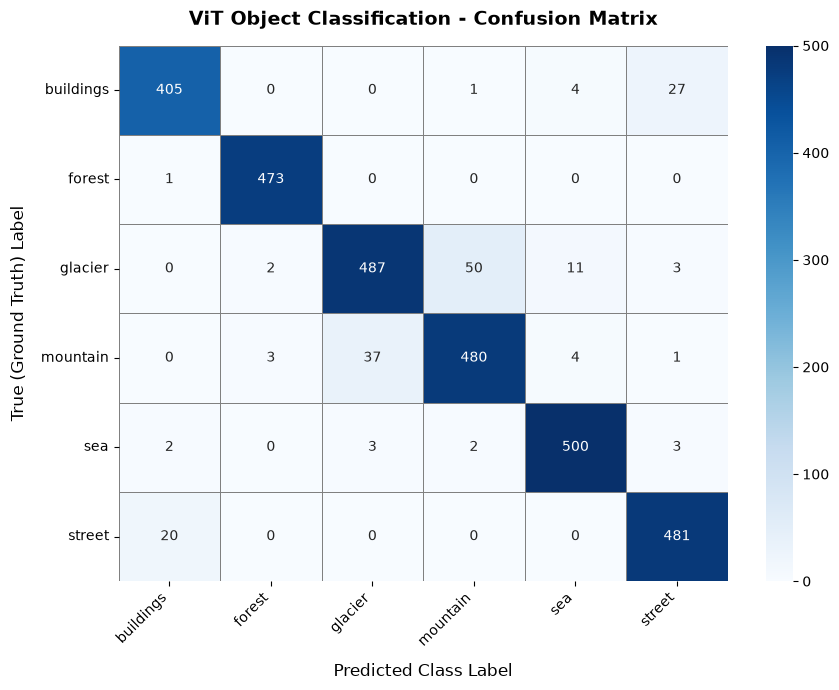

In [10]:
# Compute and Plot Confusion Matrix Heatmap
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm, 
    annot=True, 
    fmt="d", 
    cmap="Blues", 
    xticklabels=labels, 
    yticklabels=labels,
    cbar=True,
    linewidths=0.5,
    linecolor="gray"
)
plt.title("ViT Object Classification - Confusion Matrix", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Predicted Class Label", fontsize=12, labelpad=10)
plt.ylabel("True (Ground Truth) Label", fontsize=12, labelpad=10)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [13]:
# Programmatic Diagnosis: Identify Confused / Struggling Classes
print("DIAGNOSTIC REPORT: VISUAL CLASS CONFUSION ANALYSIS")

misclassifications_found = False

# Inspect off-diagonal elements in the confusion matrix (where True != Predicted)
for i in range(len(labels)):
    for j in range(len(labels)):
        if i != j and cm[i, j] > 0:
            misclassifications_found = True
            true_class = labels[i]
            pred_class = labels[j]
            count = cm[i, j]
            total_true = np.sum(cm[i, :])
            percentage = (count / total_true) * 100 if total_true > 0 else 0
            
            print(f"  • True '{true_class}' misclassified as '{pred_class}': "
                  f"{count} samples ({percentage:.1f}% of true '{true_class}' instances)")

if not misclassifications_found:
    print(" Perfect classification! No class confusion detected on the test set.")
else:
    # Calculate recall per class to find the lowest-performing category
    recalls = np.diag(cm) / np.sum(cm, axis=1)
    worst_class_idx = np.argmin(recalls)
    print(f" Lowest Recall Category: '{labels[worst_class_idx]}' ({recalls[worst_class_idx]*100:.1f}% correct).")
    '''    
    Common Visual Overlaps in Dataset:
    • 'glacier' vs. 'mountain': Share ice/rock textures and high-altitude sky backgrounds.")
    • 'sea' vs. 'glacier': Share blue/white color spectrums and water horizon features.")
    • 'buildings' vs. 'street': Share urban structures and road geometries.")
    '''

DIAGNOSTIC REPORT: VISUAL CLASS CONFUSION ANALYSIS
  • True 'buildings' misclassified as 'mountain': 1 samples (0.2% of true 'buildings' instances)
  • True 'buildings' misclassified as 'sea': 4 samples (0.9% of true 'buildings' instances)
  • True 'buildings' misclassified as 'street': 27 samples (6.2% of true 'buildings' instances)
  • True 'forest' misclassified as 'buildings': 1 samples (0.2% of true 'forest' instances)
  • True 'glacier' misclassified as 'forest': 2 samples (0.4% of true 'glacier' instances)
  • True 'glacier' misclassified as 'mountain': 50 samples (9.0% of true 'glacier' instances)
  • True 'glacier' misclassified as 'sea': 11 samples (2.0% of true 'glacier' instances)
  • True 'glacier' misclassified as 'street': 3 samples (0.5% of true 'glacier' instances)
  • True 'mountain' misclassified as 'forest': 3 samples (0.6% of true 'mountain' instances)
  • True 'mountain' misclassified as 'glacier': 37 samples (7.0% of true 'mountain' instances)
  • True 'mountain'

In [6]:
# Load Fine-Tuned ViT and Generative LLM
vit_model_path = "./saved_vit_objects_model"

# Load ViT for inference
vit_processor = AutoImageProcessor.from_pretrained(vit_model_path)
vit_model = AutoModelForImageClassification.from_pretrained(vit_model_path).to(device)
vit_model.eval()

# Load Lightweight Generative LLM (e.g., Qwen2.5-0.5B-Instruct or DistilGPT2)
llm_checkpoint = "Qwen/Qwen2.5-0.5B-Instruct"

text_generator = pipeline(
    task="text-generation",
    model=llm_checkpoint,
    device=0 if device == "cuda" else -1,
    torch_dtype=torch.float16 if device == "cuda" else torch.float32
)

Loading weights: 100%|██████████| 200/200 [00:00<00:00, 925.65it/s]
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 290/290 [00:00<00:00, 390.38it/s]


In [7]:
# Cascaded Perception-to-Text Pipeline Function
def predict_and_describe_object(
    image_path: str,
    confidence_threshold: float = 0.60,
    max_new_tokens: int = 60
):
    """
    Executes end-to-end vision-to-text inference with safety guardrails:
    1. Loads and displays the input test image.
    2. Runs ViT inference to extract predicted class and softmax confidence score.
    3. Mandatory Guardrail 1: Aborts text generation if confidence &lt; threshold (0.60).
    4. Mandatory Guardrail 2: Deterministic LLM generation (do_sample=False, 
       repetition_penalty=1.2, no_repeat_ngram_size=2) to block hallucination loops.
    """
    # Load Image
    if not os.path.exists(image_path):
        print(f"Error: Image path '{image_path}' does not exist.")
        return

    raw_image = Image.open(image_path).convert("RGB")
    
    # Display the input image
    plt.figure(figsize=(5, 5))
    plt.imshow(raw_image)
    plt.axis("off")
    plt.title("Input Test Image", fontsize=12)
    plt.show()

    # Run ViT Inference
    inputs = vit_processor(images=raw_image, return_tensors="pt").to(device)
    with torch.no_grad():
        outputs = vit_model(**inputs)
        logits = outputs.logits
        probabilities = F.softmax(logits, dim=-1)
        
    top_prob, top_cat_id = torch.max(probabilities, dim=-1)
    confidence_score = top_prob.item()
    predicted_label = vit_model.config.id2label[top_cat_id.item()]

    print(f"ViT Prediction:  {predicted_label.upper()}")
    print(f"Confidence Score: {confidence_score * 100:.2f}% (Threshold: {confidence_threshold * 100:.0f}%)")

    # Guardrail 1: Confidence Threshold Check
    if confidence_score < confidence_threshold:
        print("Prediction confidence is below 60%.")
        print("Aborting LLM text generation to prevent hallucinated descriptions of uncertain visual inputs.")
        return {
            "predicted_label": predicted_label,
            "confidence": confidence_score,
            "description": None,
            "status": "ABORTED_LOW_CONFIDENCE"
        }

    # Guardrail 2: Deterministic Anti-Hallucination Prompting & Decoding Controls
    prompt = ( f"Description of a {predicted_label} (classified with" f" {confidence_score * 100:.1f}% confidence): The {predicted_label} is" " typically" )

    # Deterministic generation parameters to guarantee stability
    generation_output = text_generator(
        prompt,
        max_new_tokens=max_new_tokens,
        do_sample=False,              # Disables random sampling (greedy decoding)
        repetition_penalty=1.2,       # Penalizes repeated tokens
        no_repeat_ngram_size=2,       # Prevents 2-gram phrase looping
        pad_token_id=text_generator.tokenizer.eos_token_id
    )

    generated_text = generation_output[0]["generated_text"].strip()

    print("Grounded LLM Generated Description:")
    print(f"{generated_text}")

    return {
        "predicted_label": predicted_label,
        "confidence": confidence_score,
        "description": generated_text,
        "status": "SUCCESS"
    }

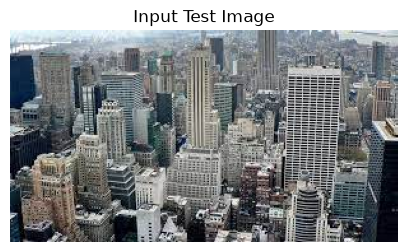

[transformers] Passing `generation_config` together with generation-related arguments=({'pad_token_id', 'max_new_tokens', 'do_sample', 'no_repeat_ngram_size', 'repetition_penalty'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


ViT Prediction:  BUILDINGS
Confidence Score: 99.17% (Threshold: 60%)


[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer Qwen2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


Grounded LLM Generated Description:
Description of a buildings (classified with 99.2% confidence): The buildings is typically located in the city center, and has an average height of around 10-35 meters depending on its location within the building complex.
The buildings are usually constructed using reinforced concrete or steel structures, which provide stability to the structure while allowing for flexibility in design and construction.

They have been designed


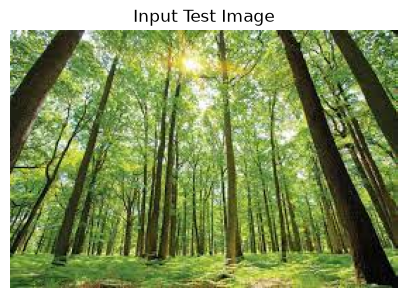

[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


ViT Prediction:  FOREST
Confidence Score: 99.98% (Threshold: 60%)
Grounded LLM Generated Description:
Description of a forest (classified with 100.0% confidence): The forest is typically composed of trees, shrubs and grasses that grow in various stages of growth including young saplings to mature trees. There are many different types of forests such as temperate rainforests, tropical rainforest, boreal forest, deciduous forest etc.
The forest has an overall structure consisting of


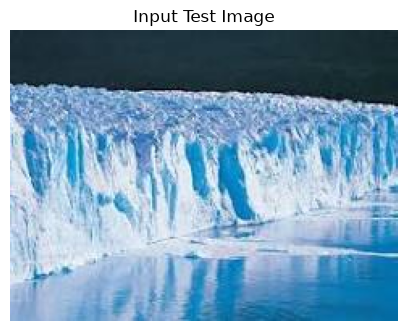

[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


ViT Prediction:  GLACIER
Confidence Score: 99.94% (Threshold: 60%)
Grounded LLM Generated Description:
Description of a glacier (classified with 99.9% confidence): The glacier is typically composed of ice and snow, which are formed from the accumulation of water in glaciers during winter months.
The glacier's surface features steep cliffs that rise to heights exceeding several hundred meters above sea level. These cliffs often form large boulders or massive blocks of rock that can be hundreds of feet tall.


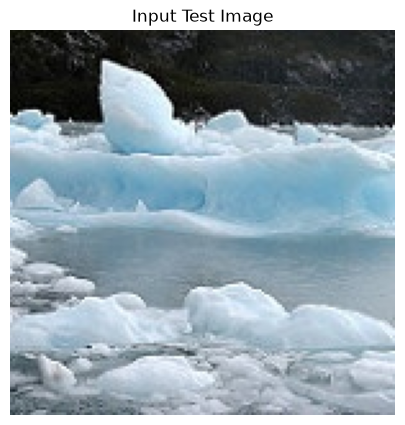

[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


ViT Prediction:  GLACIER
Confidence Score: 99.64% (Threshold: 60%)
Grounded LLM Generated Description:
Description of a glacier (classified with 99.6% confidence): The glacier is typically composed of ice and snow, which are formed from the accumulation of water in glaciers during winter months.
The glacier's surface features steep cliffs that rise to heights exceeding 100 meters above sea level. These cliffs often form large boulders or massive blocks of rock that can be several hundred feet


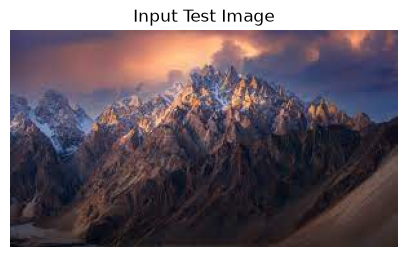

ViT Prediction:  MOUNTAIN

[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



Confidence Score: 73.57% (Threshold: 60%)
Grounded LLM Generated Description:
Description of a mountain (classified with 73.6% confidence): The mountain is typically located in the western part of China, and its peak has an elevation above 400 meters. It's characterized by steep slopes on both sides, dense forests, lush vegetation, abundant water sources, numerous rivers, lakes, gorges, karst landforms, caves, rock formations, etc


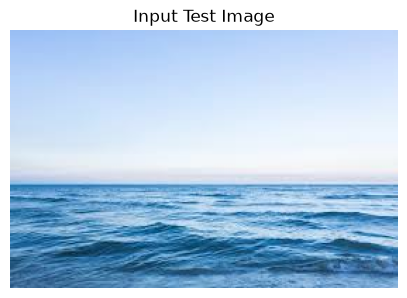

[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


ViT Prediction:  SEA
Confidence Score: 99.90% (Threshold: 60%)
Grounded LLM Generated Description:
Description of a sea (classified with 99.9% confidence): The sea is typically defined as the area between land and water, which includes oceans, seas, lakes, rivers, estuaries, bays, lagoons, etc., but not including freshwater bodies such as ponds or streams.
A: Correct
B: Incorrect

To determine whether the statement "The sea can


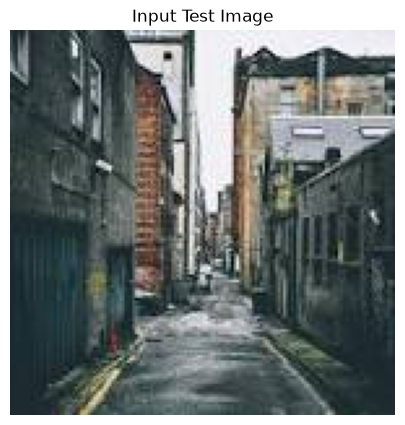

[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


ViT Prediction:  STREET
Confidence Score: 99.55% (Threshold: 60%)
Grounded LLM Generated Description:
Description of a street (classified with 99.5% confidence): The street is typically narrow and has many buildings, including residential homes, shops, restaurants, cafes, offices, schools, hospitals, parks, etc.

The streets are usually paved or have concrete surfaces that can be easily maintained by regular cleaning and maintenance.
There may also be some trees on the sides of the road to provide


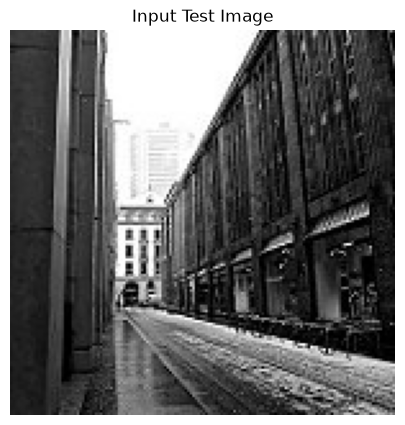

[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


ViT Prediction:  STREET
Confidence Score: 93.40% (Threshold: 60%)
Grounded LLM Generated Description:
Description of a street (classified with 93.4% confidence): The street is typically narrow and has many buildings, including residential homes, shops, restaurants, cafes, offices, schools, hospitals, parks, sports facilities, etc., which are all connected by the road network.

The streets in this area have been well maintained over time to ensure that they remain safe for pedestrians and vehicles alike


In [8]:
# Test on sample images
sample_test_images = [
    "Objects/new/building.jpg",
    "Objects/new/forest.jpg",
    "Objects/new/glacier.jpg",
    "Objects/new/glacier1.jpg",
    "Objects/new/mountains.jpg",
    "Objects/new/sea.jpg",
    "Objects/new/street.jpg",
    "Objects/new/street1.jpg"
]

for img_path in sample_test_images:
    if os.path.exists(img_path):
        predict_and_describe_object(img_path, confidence_threshold=0.60)